In [69]:
import pandas as pd
# Statistical visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
# Getting access
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [46]:
df=pd.read_csv("/content/drive/MyDrive/Retail_Pulse_Project/1_Data/After_clean_retailpulse.csv")
df

,CustomerID,Age,Gender,Region,ProductCategory,AnnualIncome,PurchaseFrequency,AnnualPurchaseAmount,CustomerTenure,DiscountUsage,ReturnRate,CustomerSegment,Recency
0,204242,50,male,north,beauty,57328.90,4.0,10206.51,3.16,0.3790,0.0929,regular,115
1,299677,36,male,east,clothing,66674.05,1.0,5497.05,7.11,0.2153,0.0251,regular,56
2,240200,37,male,central,electronics,39673.95,2.0,5850.72,6.43,0.1474,0.1273,budget,72
3,232815,36,male,south,clothing,70271.46,11.0,10174.37,2.50,0.1379,0.0133,regular,30
4,508698,30,female,west,home & kitchen,67653.56,6.0,10441.58,3.21,0.0958,0.0853,regular,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
498995,359179,49,male,east,home & kitchen,64805.16,7.0,8624.35,2.85,0.3288,0.1329,regular,55
498996,465839,33,male,central,electronics,100903.39,4.0,10645.11,5.34,0.1384,0.0431,regular,66
498997,231933,33,male,central,home & kitchen,46207.75,7.0,9266.84,9.19,0.5072,0.0686,regular,1
498998,246868,51,male,south,home & kitchen,36892.09,3.0,4569.21,5.49,0.3177,0.1984,regular,66


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499000 entries, 0 to 498999
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   CustomerID            499000 non-null  int64  
 1   Age                   499000 non-null  int64  
 2   Gender                499000 non-null  object 
 3   Region                499000 non-null  object 
 4   ProductCategory       499000 non-null  object 
 5   AnnualIncome          499000 non-null  float64
 6   PurchaseFrequency     499000 non-null  float64
 7   AnnualPurchaseAmount  499000 non-null  float64
 8   CustomerTenure        499000 non-null  float64
 9   DiscountUsage         499000 non-null  float64
 10  ReturnRate            499000 non-null  float64
 11  CustomerSegment       499000 non-null  object 
 12  Recency               499000 non-null  int64  
dtypes: float64(6), int64(3), object(4)
memory usage: 49.5+ MB


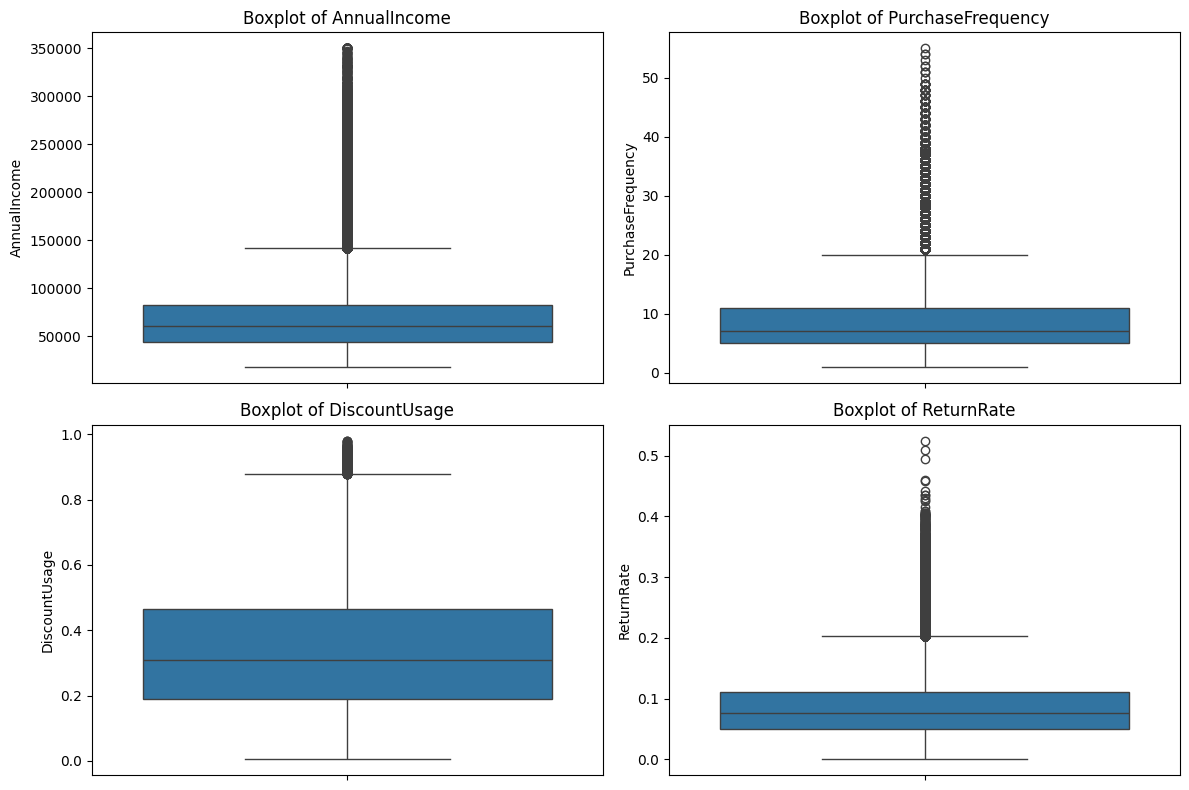

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    "AnnualIncome",
    "PurchaseFrequency",
    "DiscountUsage",
    "ReturnRate"
]

plt.figure(figsize=(12, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

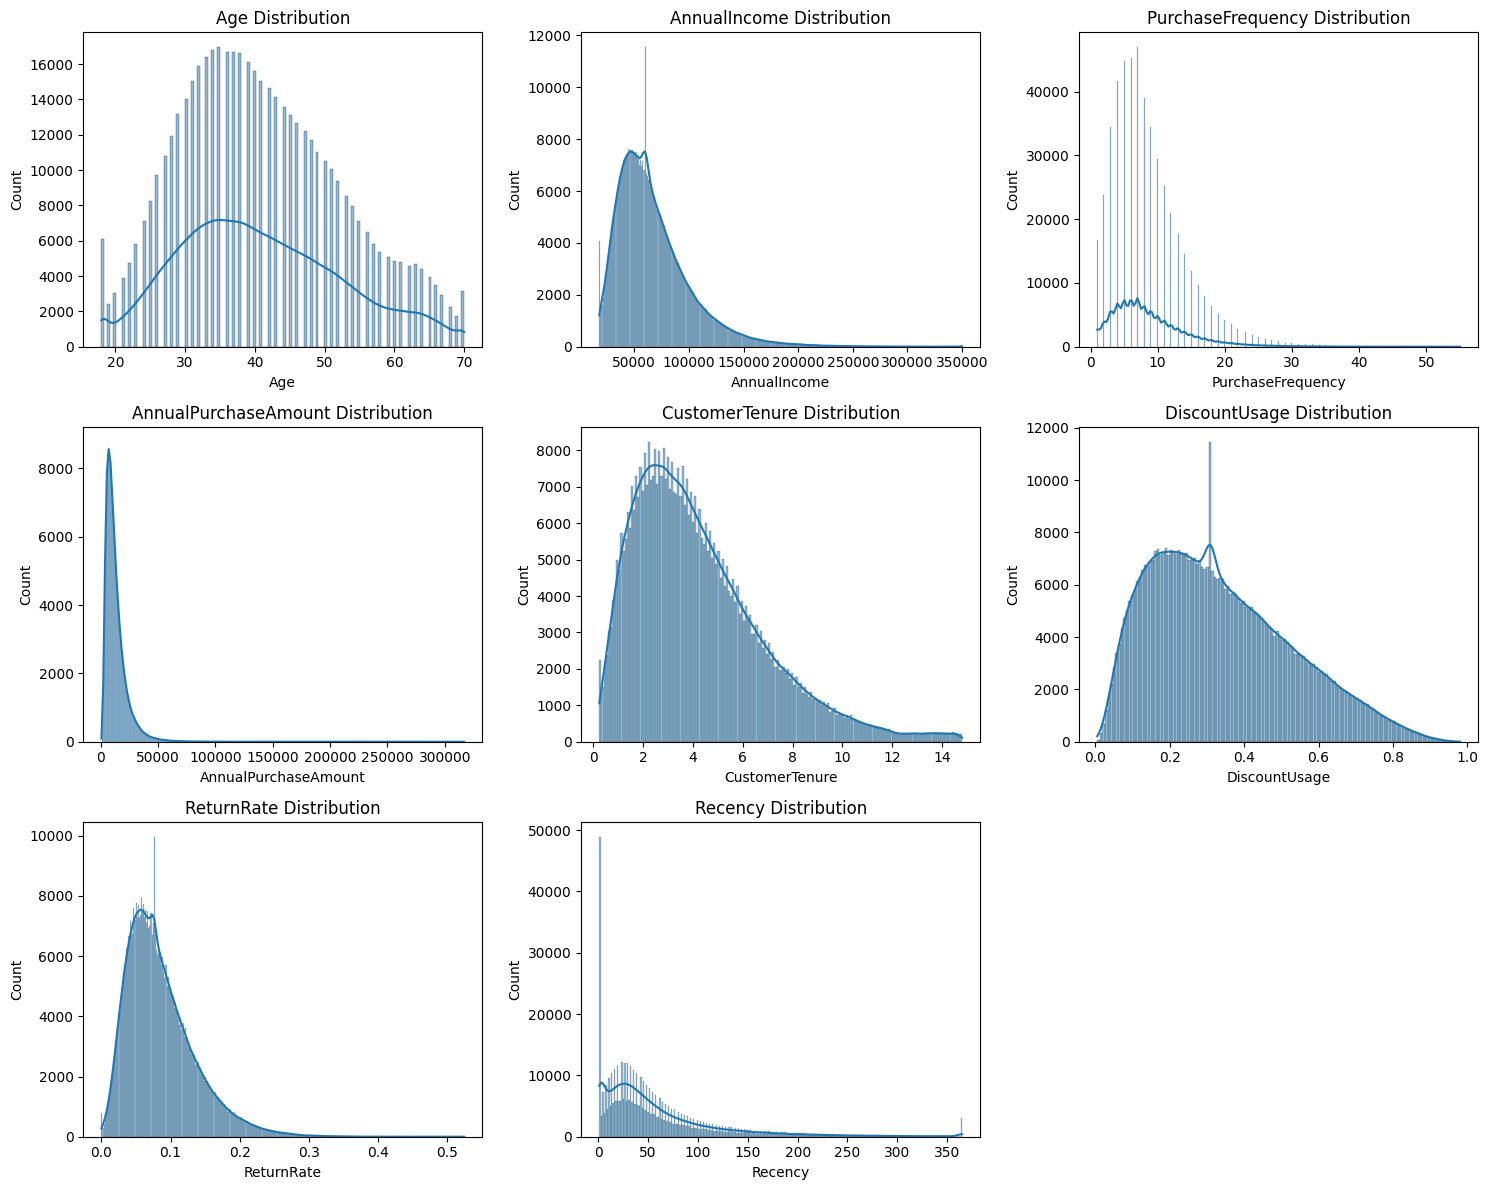

In [49]:
num_cols = [
    "Age","AnnualIncome","PurchaseFrequency",
    "AnnualPurchaseAmount","CustomerTenure",
    "DiscountUsage","ReturnRate","Recency"
]

plt.figure(figsize=(15,12))

for i,col in enumerate(num_cols,1):
    plt.subplot(3,3,i)
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"{col} Distribution")

plt.tight_layout()
plt.show()

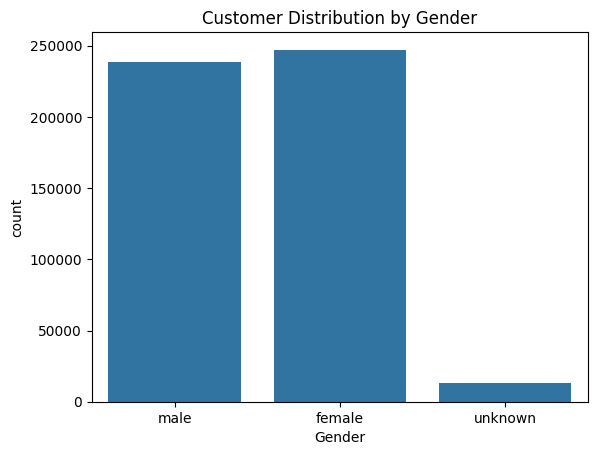

In [50]:
sns.countplot(data=df, x="Gender")
plt.title("Customer Distribution by Gender")
plt.show()

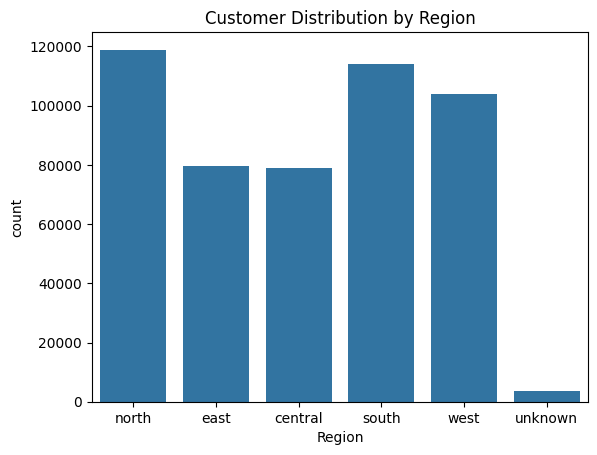

In [51]:
sns.countplot(data=df, x="Region")
plt.title("Customer Distribution by Region")
plt.show()

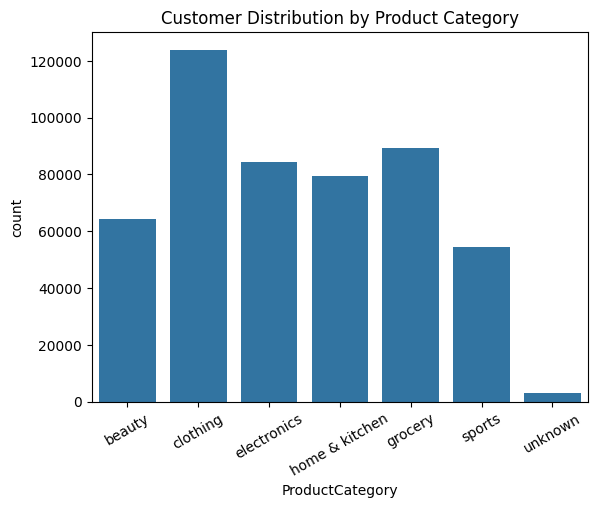

In [52]:
sns.countplot(
    data=df,
    x="ProductCategory"
)

plt.xticks(rotation=30)
plt.title("Customer Distribution by Product Category")
plt.show()

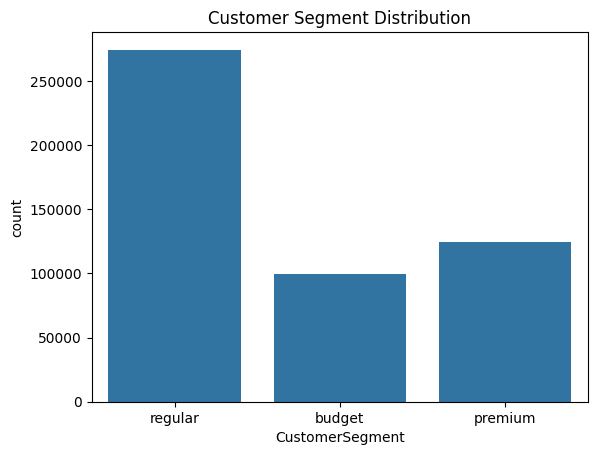

In [53]:
sns.countplot(
    data=df,
    x="CustomerSegment"
)
plt.title("Customer Segment Distribution")
plt.show()

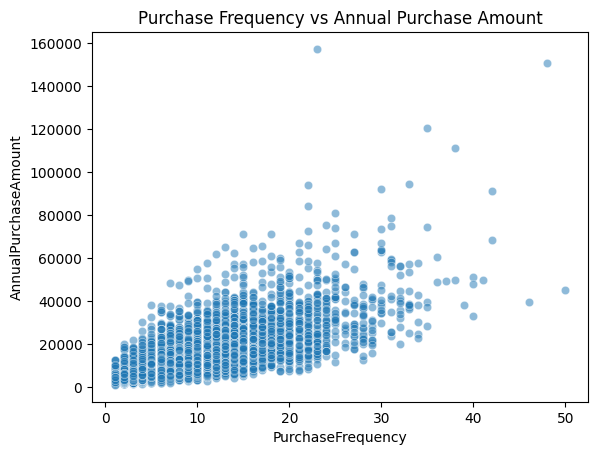

In [54]:
sample_df = df.sample(10000, random_state=42)

sns.scatterplot(
    data=sample_df,
    x="PurchaseFrequency",
    y="AnnualPurchaseAmount",
    alpha=0.5
)

plt.title("Purchase Frequency vs Annual Purchase Amount")
plt.show()

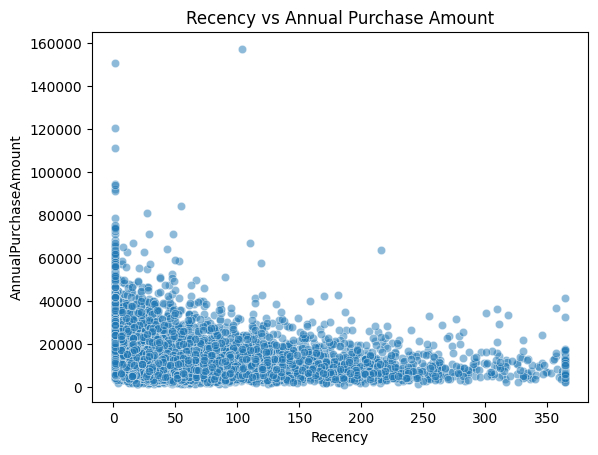

In [55]:
sns.scatterplot(
    data=sample_df,
    x="Recency",
    y="AnnualPurchaseAmount",
    alpha=0.5
)

plt.title("Recency vs Annual Purchase Amount")
plt.show()

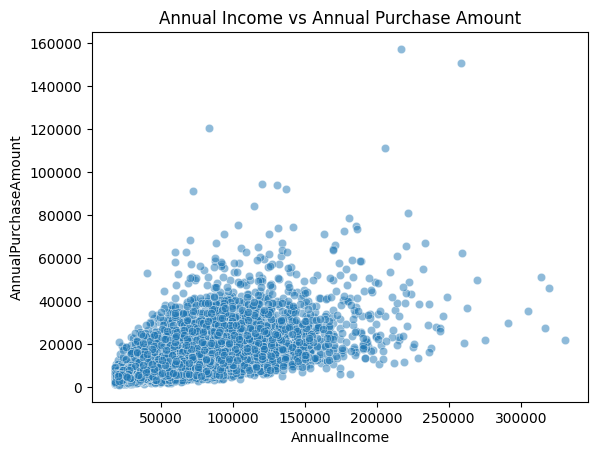

In [56]:
sns.scatterplot(
    data=sample_df,
    x="AnnualIncome",
    y="AnnualPurchaseAmount",
    alpha=0.5
)

plt.title("Annual Income vs Annual Purchase Amount")
plt.show()

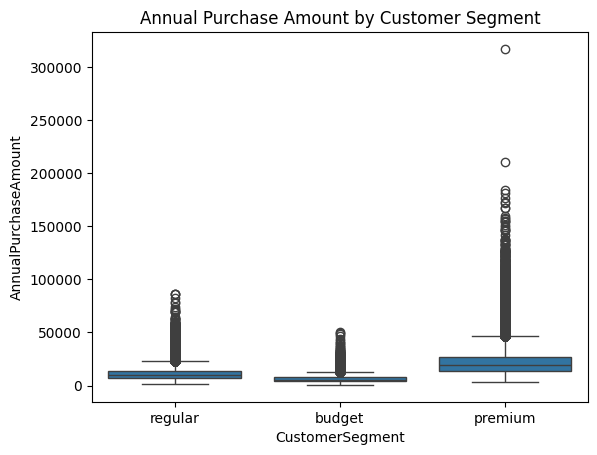

In [57]:
sns.boxplot(
    data=df,
    x="CustomerSegment",
    y="AnnualPurchaseAmount"
)

plt.title("Annual Purchase Amount by Customer Segment")
plt.show()

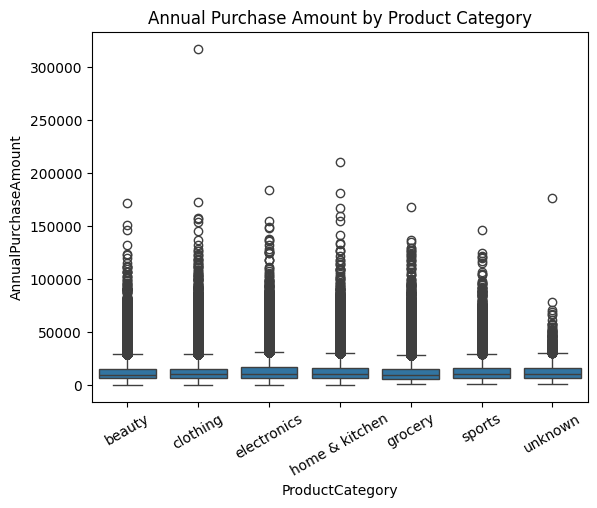

In [58]:
sns.boxplot(
    data=df,
    x="ProductCategory",
    y="AnnualPurchaseAmount"
)

plt.xticks(rotation=30)
plt.title("Annual Purchase Amount by Product Category")
plt.show()

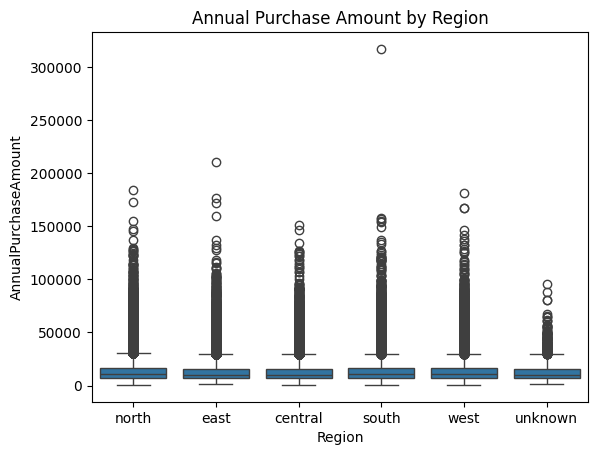

In [59]:
sns.boxplot(
    data=df,
    x="Region",
    y="AnnualPurchaseAmount"
)

plt.title("Annual Purchase Amount by Region")
plt.show()

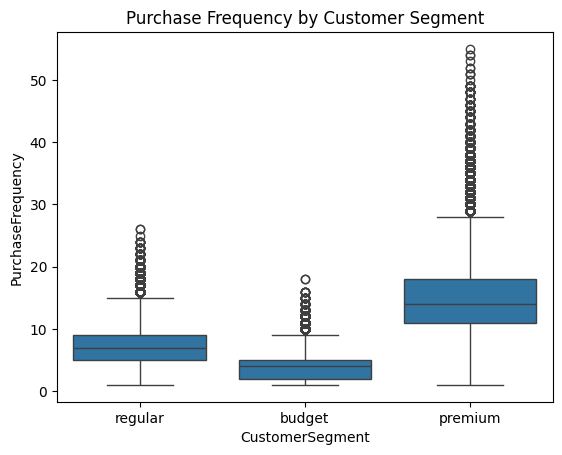

In [60]:
sns.boxplot(
    data=df,
    x="CustomerSegment",
    y="PurchaseFrequency"
)

plt.title("Purchase Frequency by Customer Segment")
plt.show()

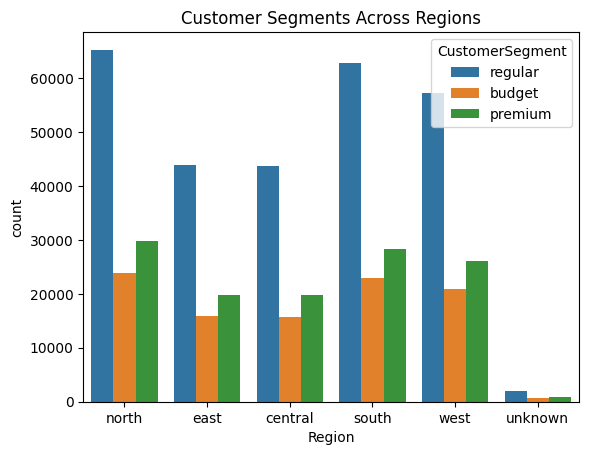

In [61]:
sns.countplot(
    data=df,
    x="Region",
    hue="CustomerSegment"
)

plt.title("Customer Segments Across Regions")
plt.show()

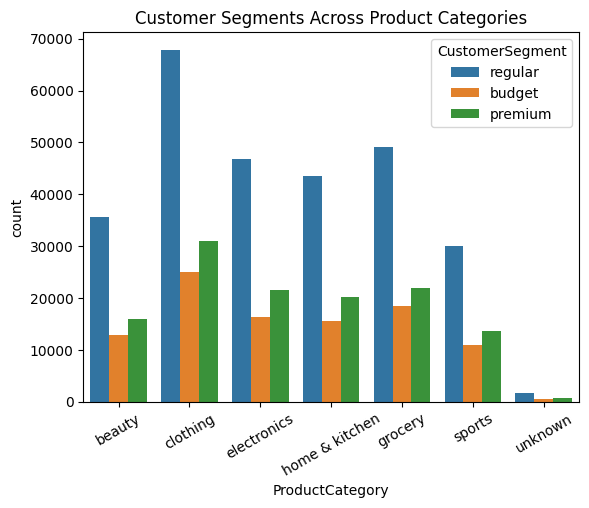

In [62]:
sns.countplot(
    data=df,
    x="ProductCategory",
    hue="CustomerSegment"
)

plt.xticks(rotation=30)
plt.title("Customer Segments Across Product Categories")
plt.show()

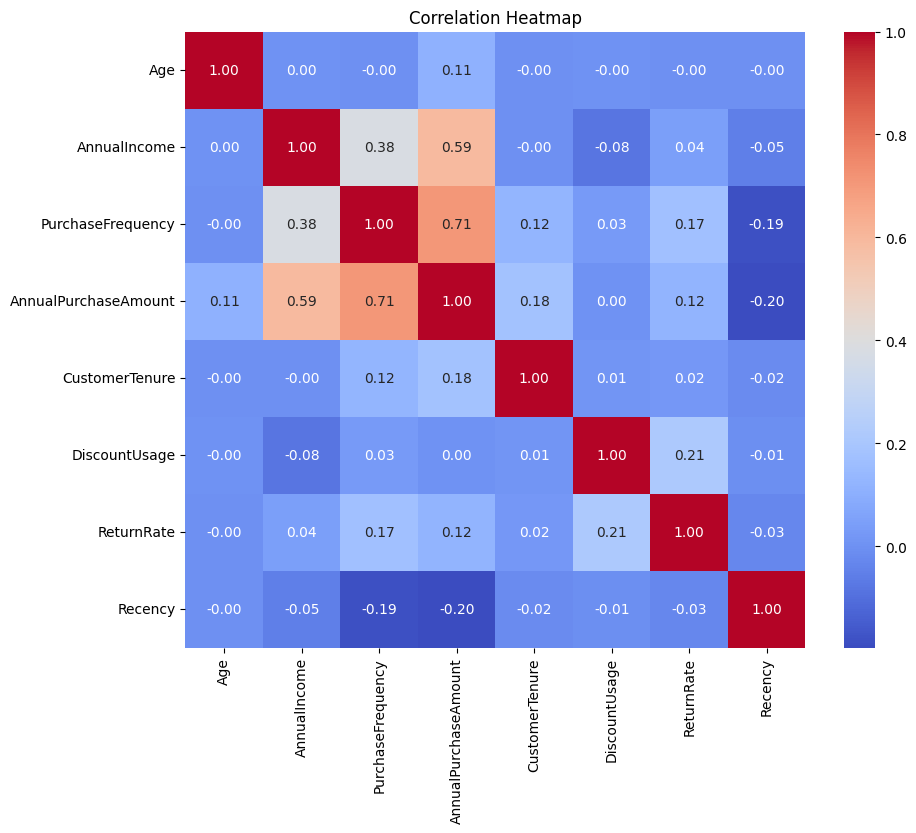

In [64]:
plt.figure(figsize=(10,8))

corr = df[num_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [70]:
sample_df = df.sample(10000, random_state=42)

fig = px.scatter(
    sample_df,
    x="PurchaseFrequency",
    y="AnnualPurchaseAmount",
    color="CustomerSegment",
    hover_data=[
        "Age",
        "AnnualIncome",
        "Region",
        "ProductCategory"
    ],
    title="Customer Spending and Purchase Frequency by Segment"
)

fig.show()

In [71]:
fig = px.scatter(
    sample_df,
    x="Recency",
    y="AnnualPurchaseAmount",
    color="CustomerSegment",
    hover_data=[
        "PurchaseFrequency",
        "AnnualIncome",
        "Region",
        "ProductCategory"
    ],
    title="Recency vs Spending by Customer Segment"
)

fig.show()

In [72]:
fig = px.box(
    df,
    x="Region",
    y="AnnualPurchaseAmount",
    color="CustomerSegment",
    title="Spending by Region and Customer Segment"
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [74]:
fig = px.histogram(
    df,
    x="Recency",
    nbins=50,
    title="Distribution of Customer Recency"
)

fig.update_layout(
    xaxis_title="Recency (Days)",
    yaxis_title="Number of Customers"
)

fig.show()

In [75]:
fig = px.scatter(
    df.sample(10000, random_state=42),
    x="Recency",
    y="AnnualPurchaseAmount",
    color="CustomerSegment",
    title="Recency vs Annual Purchase Amount"
)
fig.show()

In [76]:
fig = px.scatter(
    df.sample(10000, random_state=42),
    x="PurchaseFrequency",
    y="AnnualPurchaseAmount",
    color="CustomerSegment",
    title="Purchase Frequency vs Annual Purchase Amount"
)
fig.show()

In [77]:
fig = px.box(
    df,
    x="CustomerSegment",
    y="AnnualPurchaseAmount",
    title="Spending Distribution by Customer Segment"
)
fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [78]:
fig = px.box(
    df,
    x="ProductCategory",
    y="AnnualPurchaseAmount",
    title="Spending Distribution by Product Category"
)
fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [79]:
fig = px.histogram(
    df,
    x="Region",
    color="CustomerSegment",
    barmode="group",
    title="Customer Segments by Region"
)
fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [80]:
fig = px.scatter(
    df.sample(10000, random_state=42),
    x="PurchaseFrequency",
    y="AnnualPurchaseAmount",
    color="CustomerSegment",
    size="AnnualIncome",
    hover_data=["Age", "Region", "ProductCategory"],
    title="Customer Behavior Analysis"
)
fig.show()